In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter



In [2]:
# Read csv data
dFNA_diaux = pd.read_csv('DFNA_Yeast9_diaux_conc.csv')  
dFBA_diaux = pd.read_csv('DFBA_Yeast9_diaux_conc.csv')
dFNA_diaux_reducido = pd.read_csv('DFNA_reducido_Yeast9_diaux_conc.csv')

dFNA_aer = pd.read_csv('DFNA_Yeast9_aer_conc.csv')  
dFBA_aer = pd.read_csv('DFBA_Yeast9_aer_conc.csv')
dFNA_aer_reducido = pd.read_csv('DFNA_reducido_Yeast9_aer_conc.csv')

dFNA_anaer = pd.read_csv('DFNA_Yeast9_anaer_conc.csv')
dFBA_anaer = pd.read_csv('DFBA_Yeast9_anaer_conc.csv')
dFNA_anaer_reducido = pd.read_csv('DFNA_reducido_Yeast9_anaer_conc.csv')



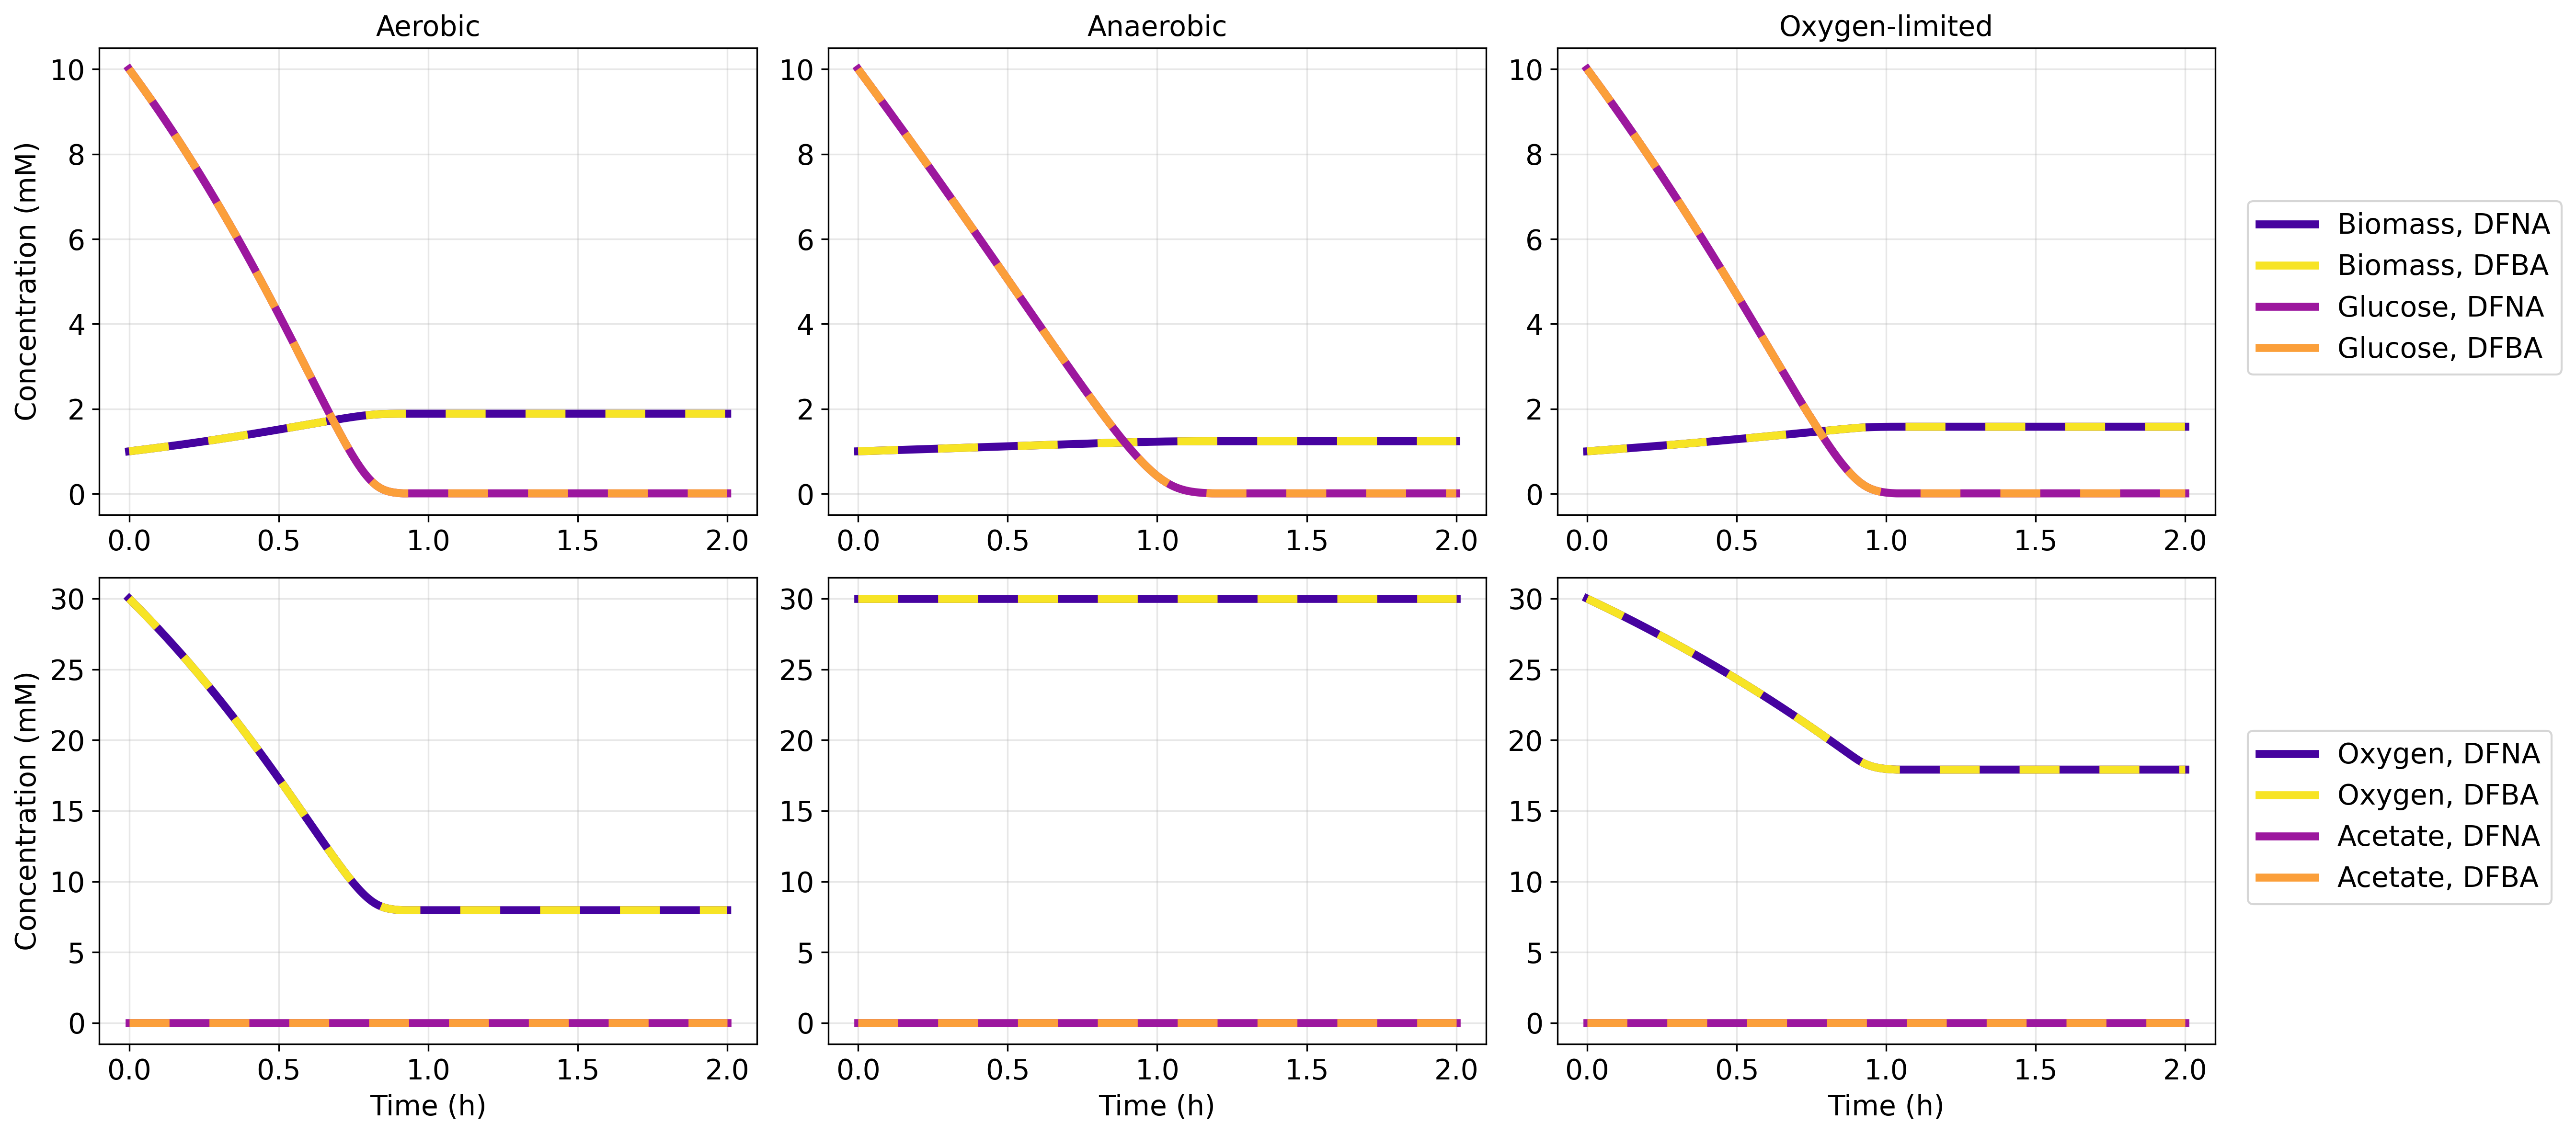

In [3]:
# Asignar colores específicos a cada variable
palette = sns.color_palette("plasma", 8)
color1  = palette[0]
color2  = sns.color_palette("plasma", 20)[-1]
color3  = palette[2]
color4  = palette[-2]
linewidth_value = 4
linewidth_seg   = 4
fontsize_legend = 14
fontsize_labels = 14
fontsize_ticks  = 14
fontsize_title  = 14
xticks = [0, 0.5, 1, 1.5, 2]

# Crear la figura con subplots 2 filas x 4 columnas (última columna para leyenda)
fig, axs = plt.subplots(2, 3, figsize=(18, 8), dpi=300)

casos = [
    ('Aerobic', dFNA_aer, dFBA_aer),
    ('Anaerobic', dFNA_anaer, dFBA_anaer),
    ('Oxygen-limited', dFNA_diaux, dFBA_diaux)
]

for col, (titulo, df_DFNA, df_DFBA) in enumerate(casos):
    # Biomass y Glucose
    axs[0, col].plot(df_DFNA['Time'], df_DFNA['Biomass'], color=color1, label='Biomass, DFNA', linewidth=linewidth_value)
    axs[0, col].plot(df_DFBA['Time'], df_DFBA['Biomass'], '--', color=color2, label='Biomass, DFBA', linewidth=linewidth_seg, dashes=(5, 5))
    axs[0, col].plot(df_DFNA['Time'], df_DFNA['Glucose'], color=color3, label='Glucose, DFNA', linewidth=linewidth_value)
    axs[0, col].plot(df_DFBA['Time'], df_DFBA['Glucose'], '--', color=color4, label='Glucose, DFBA', linewidth=linewidth_seg, dashes=(5, 5))
    axs[0, col].set_title(titulo, fontsize=fontsize_title)
    axs[0, col].tick_params(axis='x', labelsize=fontsize_ticks)
    axs[0, col].set_xticks(xticks)
    axs[0, col].tick_params(axis='y', labelsize=fontsize_ticks)
    axs[0, col].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x)}"))
    axs[0, col].grid(True, alpha=0.3)
    if col == 0:
        axs[0, col].set_ylabel('Concentration (mM)', fontsize=fontsize_labels)

    # Oxygen y Acetate
    axs[1, col].plot(df_DFNA['Time'], df_DFNA['Oxygen'], color=color1, label='Oxygen, DFNA', linewidth=linewidth_value)
    axs[1, col].plot(df_DFBA['Time'], df_DFBA['Oxygen'], '--', color=color2, label='Oxygen, DFBA', linewidth=linewidth_seg, dashes=(5, 5))
    axs[1, col].plot(df_DFNA['Time'], df_DFNA['Acetate'], color=color3, label='Acetate, DFNA', linewidth=linewidth_value)
    axs[1, col].plot(df_DFBA['Time'], df_DFBA['Acetate'], '--', color=color4, label='Acetate, DFBA', linewidth=linewidth_seg, dashes=(5, 5))
    axs[1, col].set_xlabel('Time (h)', fontsize=fontsize_labels)
    axs[1, col].tick_params(axis='x', labelsize=fontsize_ticks)
    axs[1, col].tick_params(axis='y', labelsize=fontsize_ticks)
    axs[1, col].set_xticks(xticks)
    axs[1, col].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x)}"))
    axs[1, col].grid(True, alpha=0.3)
    if col == 0:
        axs[1, col].set_ylabel('Concentration (mM)', fontsize=fontsize_labels)

# Crear handles personalizados para la leyenda
custom_lines = [
    Line2D([0], [0], color=color1, lw=linewidth_value, label='DFNA'),
    Line2D([0], [0], color=color2, lw=linewidth_seg, label='DFBA'),
    Line2D([0], [0], color=color3, lw=linewidth_value, label='DFNA'),
    Line2D([0], [0], color=color4, lw=linewidth_seg, label='DFBA')
]

# Añadir la leyenda en la última columna de cada fila
legend_names = [['Biomass, DFNA', 'Biomass, DFBA', 'Glucose, DFNA', 'Glucose, DFBA'],
                     ['Oxygen, DFNA', 'Oxygen, DFBA', 'Acetate, DFNA', 'Acetate, DFBA']]
for row in range(2):
    axs[row, 2].legend(
        handles=custom_lines,
        loc=(1.05, 0.3),
        labels=legend_names[row],
        ncol=1, fontsize=fontsize_legend
    )

plt.tight_layout()
# plt.savefig('../Figs/ecolicore_concentrations_comparison.svg', bbox_inches='tight', dpi=600)
plt.show()


In [4]:
def RMSE(true, pred):
    return np.sqrt(np.mean((true - pred)**2))

# Calcular RMSE para cada variable y condición

condiciones = {
    'Aerobic': (dFNA_aer, dFBA_aer),
    'Anaerobic': (dFNA_anaer, dFBA_anaer),
    'Diauxic': (dFNA_diaux, dFBA_diaux)
}

resultados = []

for cond, (df_true, df_pred) in condiciones.items():
    # Suponemos que las columnas y el orden son iguales
    for var in df_true.columns[1:]:  # omitir 'Time'
        # Interpolar para asegurar alineación de tiempos
        pred_interp = np.interp(df_true['Time'], df_pred['Time'], df_pred[var])
        rmse = RMSE(df_true[var], pred_interp)
        resultados.append({'Condition': cond, 'Variable': var, 'RMSE': rmse})

# Crear DataFrame de resultados
rmse_df = pd.DataFrame(resultados)
rmse_pivot = rmse_df.pivot(index='Variable', columns='Condition', values='RMSE')
display(rmse_pivot)

Condition,Aerobic,Anaerobic,Diauxic
Variable,,,
Acetate,0.000000,0.000000e+00,0.000000e+00
Ammonium,0.000315,4.202936e-08,8.346626e-08
Biomass,0.000049,6.601459e-09,1.516152e-08
CO2,0.001309,9.858157e-08,1.525399e-07
Ethanol,0.000000,1.288324e-07,1.782201e-07
Glucose,0.000552,1.015184e-08,1.714619e-08
Oxygen,0.001210,0.000000e+00,2.898298e-08


In [5]:
# Calcular RMSE para cada variable y condición

condiciones = {
    'Aerobic': (dFNA_aer_reducido, dFBA_aer),
    'Anaerobic': (dFNA_anaer_reducido, dFBA_anaer),
    'Diauxic': (dFNA_diaux_reducido, dFBA_diaux)
}

resultados = []

for cond, (df_true, df_pred) in condiciones.items():
    # Suponemos que las columnas y el orden son iguales
    for var in df_true.columns[1:]:  # omitir 'Time'
        # Interpolar para asegurar alineación de tiempos
        pred_interp = np.interp(df_true['Time'], df_pred['Time'], df_pred[var])
        rmse = RMSE(df_true[var], pred_interp)
        resultados.append({'Condition': cond, 'Variable': var, 'RMSE': rmse})

# Crear DataFrame de resultados
rmse_df = pd.DataFrame(resultados)
rmse_pivot = rmse_df.pivot(index='Variable', columns='Condition', values='RMSE')
display(rmse_pivot)

Condition,Aerobic,Anaerobic,Diauxic
Variable,,,
Acetate,0.000000,0.000000e+00,0.000000e+00
Ammonium,0.000315,1.144165e-07,1.100152e-07
Biomass,0.000049,3.660874e-08,2.218606e-08
CO2,0.001309,7.060712e-07,2.045170e-07
Ethanol,0.000000,9.485230e-07,2.548859e-07
Glucose,0.000552,5.669458e-08,2.451752e-08
Oxygen,0.001210,0.000000e+00,3.918476e-08
